# 02 · Modelling: experiments and final model

## 0. Setup

In [10]:
%pip install -q mlflow dagshub

In [11]:
import os, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score, mean_absolute_error
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Court-Recovery-Model")
else:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "..")).resolve()

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROC_DIR = PROJECT_DIR / "data" / "processed"
FIG_DIR = PROJECT_DIR / "reports" / "figures"
MODEL_DIR = PROJECT_DIR / "models"
for p in (FIG_DIR, MODEL_DIR):
    p.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

FIXED_COST, VAR_COST_RATE = 500, 0.10

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
USE_MLFLOW = True
DAGSHUB_USER = "slosa23"
DAGSHUB_REPO = "Court-Recovery-Model"

try:
    import mlflow
    token = None
    if IN_COLAB:
        from google.colab import userdata
        token = userdata.get("DAGSHUB_TOKEN")
    token = token or os.environ.get("DAGSHUB_TOKEN")
    if not token:
        raise RuntimeError("no DAGSHUB_TOKEN found")
    os.environ["MLFLOW_TRACKING_USERNAME"] = DAGSHUB_USER
    os.environ["MLFLOW_TRACKING_PASSWORD"] = token
    mlflow.set_tracking_uri(f"https://dagshub.com/{DAGSHUB_USER}/{DAGSHUB_REPO}.mlflow")
    mlflow.set_experiment("court_recovery_modeling")
    print("MLflow tracking:", mlflow.get_tracking_uri())
except Exception as e:
    USE_MLFLOW = False
    print("MLflow disabled:", e)

ALREADY_LOGGED = {"baseline", "experiment_A", "experiment_B"}

def log_run(name, params, metrics, fig=None, tags=None):
    """Log one experiment. Never breaks the notebook if tracking fails."""
    if not USE_MLFLOW or (tags or {}).get("stage") in ALREADY_LOGGED:
        return
    if not USE_MLFLOW:
        return
    try:
        with mlflow.start_run(run_name=name):
            mlflow.set_tags(tags or {})
            mlflow.log_params({k: str(v) for k, v in params.items()})
            mlflow.log_metrics({k: float(v) for k, v in metrics.items() if pd.notna(v)})
            if fig is not None:
                mlflow.log_figure(fig, f"{name}.png")
    except Exception as e:
        print(f"MLflow logging failed for {name}: {e}")

MLflow tracking: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow


## 1. Data and features

In [13]:
pq = PROC_DIR / "model_dataset.parquet"
data = pd.read_parquet(pq) if pq.exists() else pd.read_csv(PROC_DIR / "model_dataset.csv")
data = data[data.in_scope == 1].reset_index(drop=True)

data["repaid_share"] = 1 - data.outst / data.principal

fdict = pd.read_csv(RAW_DIR / "feature_dictionary.csv").set_index("column")
FEATURES = ([c for c in data.columns if c.startswith("feature_")]
            + ["outst", "principal", "n_loans", "repaid_share"])
EXTRA_DESC = {"outst": "Outstanding balance at court start", "principal": "Original principal",
              "n_loans": "Number of unsecured loans", "repaid_share": "Share of principal repaid before default",
              "feature_011_missing": "No deposit or savings product", "feature_039_missing": "No declared income on file"}
def describe(c):
    return EXTRA_DESC.get(c, fdict.description.get(c, c))

GEL_FEATURES = [c for c in FEATURES if c in fdict.index and fdict.loc[c, "unit"] == "GEL"] + ["outst", "principal"]

train = data[data.split == "train"].copy()
valid = data[data.split == "valid"].copy()
test = data[data.split == "test"].copy()
print(f"Features: {len(FEATURES)}")
display(pd.DataFrame({s: {"rows": len(d), "any_payment": d.any_payment.mean(), "profitable": d.profitable.mean(),
                          "net_value_total": d.net_value_24m.sum()} for s, d in
                      [("train", train), ("valid", valid), ("test", test)]}).T)

Features: 53


,rows,any_payment,profitable,net_value_total
train,"12,550.000",0.453,0.165,"-5,524,794.155"
valid,"4,261.000",0.461,0.168,"-1,939,659.265"
test,"6,359.000",0.437,0.142,"-3,706,895.867"


## 2. Evaluation framework


In [14]:
def evaluate(df, select, name, net=None):
    net = df.net_value_24m.values if net is None else np.asarray(net)
    select = np.asarray(select, dtype=bool)
    sue_all, oracle = net.sum(), net.clip(min=0).sum()
    value = net[select].sum()
    return {"strategy": name, "cases": int(select.sum()), "share_sued": select.mean(),
            "net_value": value, "vs_sue_all": value - sue_all,
            "capture": (value - sue_all) / (oracle - sue_all)}

def profit_curve(df, score, net=None):
    net = df.net_value_24m.values if net is None else np.asarray(net)
    order = np.argsort(-np.asarray(score))
    return np.r_[0, net[order].cumsum()]

def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1

## 3. Baselines

In [15]:
baselines = [evaluate(valid, np.ones(len(valid)), "sue everyone"),
             evaluate(valid, np.zeros(len(valid)), "sue no one"),
             evaluate(valid, valid.net_value_24m > 0, "oracle (perfect foresight)")]

thresholds = np.unique(np.quantile(valid.outst, np.linspace(0, 0.99, 100)))
bal_vals = [valid.net_value_24m[valid.outst > t].sum() for t in thresholds]
BEST_BAL = float(thresholds[int(np.argmax(bal_vals))])
baselines.append(evaluate(valid, valid.outst > BEST_BAL, f"balance > {BEST_BAL:,.0f} GEL"))

best_rule = (-np.inf, None, None)
for t in np.quantile(valid.outst, np.linspace(0, 0.95, 20)):
    for sc in np.quantile(valid.feature_031, np.linspace(0, 0.9, 10)):
        v = valid.net_value_24m[(valid.outst > t) & (valid.feature_031 > sc)].sum()
        if v > best_rule[0]:
            best_rule = (v, float(t), float(sc))
_, RULE_BAL, RULE_SCORE = best_rule
RULE_NAME = f"rule: balance > {RULE_BAL:,.0f} & bureau score > {RULE_SCORE:.0f}"
rule_sel = lambda df: (df.outst > RULE_BAL) & (df.feature_031 > RULE_SCORE)
baselines.append(evaluate(valid, rule_sel(valid), RULE_NAME))

baseline_tab = pd.DataFrame(baselines).set_index("strategy")
display(baseline_tab)
for r in baselines:
    log_run(f"baseline | {r['strategy']}", {"type": "rule"},
            {"valid_net_value": r["net_value"], "valid_capture": r["capture"], "valid_cases": r["cases"]},
            tags={"stage": "baseline"})

,cases,share_sued,net_value,vs_sue_all,capture
strategy,,,,,
sue everyone,4261,1.000,"-1,939,659.265",0.000,0.000
sue no one,0,0.000,0.000,"1,939,659.265",0.481
oracle (perfect foresight),715,0.168,"2,089,906.993","4,029,566.258",1.000
"balance > 42,866 GEL",43,0.010,"11,641.857","1,951,301.122",0.484
"rule: balance > 7,094 & bureau score > 367",295,0.069,"317,470.507","2,257,129.772",0.560


## 4. Experiment A — P(any payment)

In [16]:
def linear_preprocessor():
    other = [c for c in FEATURES if c not in GEL_FEATURES]
    return ColumnTransformer([
        ("gel", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p), StandardScaler()), GEL_FEATURES),
        ("other", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), other),
    ])

def make_logit(C):
    return Pipeline([("prep", linear_preprocessor()),
                     ("model", LogisticRegression(C=C, max_iter=3000))])

def make_hgb_clf(lr, leaves, min_leaf):
    return HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, min_samples_leaf=min_leaf,
                                          l2_regularization=1.0, max_iter=1000, early_stopping=True,
                                          validation_fraction=0.15, n_iter_no_change=30, random_state=SEED)

GRID_HGB = [(lr, leaves, ml) for lr in (0.03, 0.08) for leaves in (7, 15, 31) for ml in (50, 200)]

In [17]:
results_a = []
for C in (0.01, 0.1, 1.0):
    m = make_logit(C).fit(train[FEATURES], train.any_payment)
    p = m.predict_proba(valid[FEATURES])[:, 1]
    results_a.append({"model": "logit", "params": {"C": C}, "est": m, "valid_gini": gini(valid.any_payment, p)})

for lr, leaves, ml in GRID_HGB:
    m = make_hgb_clf(lr, leaves, ml).fit(train[FEATURES], train.any_payment)
    p = m.predict_proba(valid[FEATURES])[:, 1]
    results_a.append({"model": "hgb", "params": {"learning_rate": lr, "max_leaf_nodes": leaves, "min_samples_leaf": ml},
                      "est": m, "valid_gini": gini(valid.any_payment, p)})

for r in results_a:
    log_run(f"A | any_payment | {r['model']}", {**r["params"], "model": r["model"], "target": "any_payment"},
            {"valid_gini": r["valid_gini"], "valid_auc": (r["valid_gini"] + 1) / 2}, tags={"stage": "experiment_A"})

tab_a = pd.DataFrame([{"model": r["model"], **r["params"], "valid_gini": r["valid_gini"]} for r in results_a])
display(tab_a.sort_values("valid_gini", ascending=False).head(8))
best_a = {m: max([r for r in results_a if r["model"] == m], key=lambda r: r["valid_gini"]) for m in ("logit", "hgb")}
print({m: round(r["valid_gini"], 3) for m, r in best_a.items()})

,model,C,valid_gini,learning_rate,max_leaf_nodes,min_samples_leaf
10,hgb,NaN,0.327,0.080,7.000,200.000
4,hgb,NaN,0.326,0.030,7.000,200.000
0,logit,0.010,0.324,NaN,NaN,NaN
12,hgb,NaN,0.323,0.080,15.000,200.000
6,hgb,NaN,0.323,0.030,15.000,200.000
3,hgb,NaN,0.323,0.030,7.000,50.000
1,logit,0.100,0.322,NaN,NaN,NaN
2,logit,1.000,0.322,NaN,NaN,NaN


{'logit': np.float64(0.324), 'hgb': np.float64(0.327)}


## 5. Experiment B — recovery rate given payment

In [18]:
def make_ridge(alpha):
    return Pipeline([("prep", linear_preprocessor()), ("model", Ridge(alpha=alpha))])

def make_hgb_reg(lr, leaves, min_leaf, loss="squared_error"):
    return HistGradientBoostingRegressor(loss=loss, learning_rate=lr, max_leaf_nodes=leaves, min_samples_leaf=min_leaf,
                                         l2_regularization=1.0, max_iter=1000, early_stopping=True,
                                         validation_fraction=0.15, n_iter_no_change=30, random_state=SEED)

tr_pos, va_pos = train[train.any_payment == 1], valid[valid.any_payment == 1]

def rate_metrics(pred):
    pred = np.clip(pred, 0, 1)
    return {"valid_spearman": pd.Series(pred).corr(pd.Series(va_pos.recovery_rate_24m.values), method="spearman"),
            "valid_mae": mean_absolute_error(va_pos.recovery_rate_24m, pred)}

results_b = []
for a in (1.0, 10.0, 100.0):
    m = make_ridge(a).fit(tr_pos[FEATURES], tr_pos.recovery_rate_24m)
    results_b.append({"model": "ridge", "params": {"alpha": a}, "est": m, **rate_metrics(m.predict(va_pos[FEATURES]))})
for lr, leaves, ml in GRID_HGB:
    m = make_hgb_reg(lr, leaves, ml).fit(tr_pos[FEATURES], tr_pos.recovery_rate_24m)
    results_b.append({"model": "hgb", "params": {"learning_rate": lr, "max_leaf_nodes": leaves, "min_samples_leaf": ml},
                      "est": m, **rate_metrics(m.predict(va_pos[FEATURES]))})

for r in results_b:
    log_run(f"B | rate_given_payment | {r['model']}", {**r["params"], "model": r["model"], "target": "recovery_rate|payment"},
            {"valid_spearman": r["valid_spearman"], "valid_mae": r["valid_mae"]}, tags={"stage": "experiment_B"})

tab_b = pd.DataFrame([{"model": r["model"], **r["params"], "valid_spearman": r["valid_spearman"],
                       "valid_mae": r["valid_mae"]} for r in results_b])
display(tab_b.sort_values("valid_spearman", ascending=False).head(8))
best_b = {m: max([r for r in results_b if r["model"] == m], key=lambda r: r["valid_spearman"]) for m in ("ridge", "hgb")}
print({m: round(r["valid_spearman"], 3) for m, r in best_b.items()})

,model,alpha,valid_spearman,valid_mae,learning_rate,max_leaf_nodes,min_samples_leaf
0,ridge,1.000,0.467,0.187,NaN,NaN,NaN
1,ridge,10.000,0.467,0.187,NaN,NaN,NaN
2,ridge,100.000,0.467,0.188,NaN,NaN,NaN
3,hgb,NaN,0.447,0.191,0.030,7.000,50.000
4,hgb,NaN,0.446,0.190,0.030,7.000,200.000
10,hgb,NaN,0.444,0.189,0.080,7.000,200.000
12,hgb,NaN,0.443,0.190,0.080,15.000,200.000
6,hgb,NaN,0.443,0.191,0.030,15.000,200.000


{'ridge': np.float64(0.467), 'hgb': np.float64(0.447)}


## 6. Experiments C and D — challengers

In [19]:
results_c = []
for lr, leaves, ml in GRID_HGB[::2]:
    m = make_hgb_reg(lr, leaves, ml, loss="poisson").fit(train[FEATURES], train.recovery_rate_24m)
    rate = np.clip(m.predict(valid[FEATURES]), 0, 1)
    results_c.append({"params": {"learning_rate": lr, "max_leaf_nodes": leaves, "min_samples_leaf": ml}, "est": m,
                      "valid_spearman_all": pd.Series(rate).corr(valid.recovery_rate_24m.reset_index(drop=True), method="spearman")})
best_c = max(results_c, key=lambda r: r["valid_spearman_all"])

results_d = []
for lr, leaves, ml in GRID_HGB[::2]:
    m = make_hgb_clf(lr, leaves, ml).fit(train[FEATURES], train.profitable)
    results_d.append({"params": {"learning_rate": lr, "max_leaf_nodes": leaves, "min_samples_leaf": ml}, "est": m,
                      "valid_gini": gini(valid.profitable, m.predict_proba(valid[FEATURES])[:, 1])})
best_d = max(results_d, key=lambda r: r["valid_gini"])

for r in results_c:
    log_run("C | single_rate | hgb_poisson", {**r["params"], "target": "recovery_rate_24m"},
            {"valid_spearman_all": r["valid_spearman_all"]}, tags={"stage": "experiment_C"})
for r in results_d:
    log_run("D | profitable_clf | hgb", {**r["params"], "target": "profitable"},
            {"valid_gini": r["valid_gini"]}, tags={"stage": "experiment_D"})
print(f"C best Spearman (all clients): {best_c['valid_spearman_all']:.3f}   D best Gini (profitable): {best_d['valid_gini']:.3f}")

🏃 View run C | single_rate | hgb_poisson at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/c9b2cb4de14045efb270cc6110d5ccf2
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0
🏃 View run C | single_rate | hgb_poisson at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/6775a934a9f1488c81419ee740b95c70
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0
🏃 View run C | single_rate | hgb_poisson at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/a306f2f4a64d40ffbf7a65b984fc8d45
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0
🏃 View run C | single_rate | hgb_poisson at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/c9ec82094f264b94a695b5114f6ee8f3
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0
🏃 Vi

## 7. Compare strategies in money (validation)

In [20]:
def expected_net(df, p_model, r_model):
    p = p_model.predict_proba(df[FEATURES])[:, 1]
    rate = np.clip(r_model.predict(df[FEATURES]), 0, 1)
    return p * rate * df.outst.values - df.court_cost.values, p, rate

strategies, curves = [], {}
for pa in ("logit", "hgb"):
    for rb in ("ridge", "hgb"):
        en, _, _ = expected_net(valid, best_a[pa]["est"], best_b[rb]["est"])
        name = f"two-part: P={pa}, rate={rb}"
        strategies.append(evaluate(valid, en > 0, name)); curves[name] = profit_curve(valid, en)

en_c = np.clip(best_c["est"].predict(valid[FEATURES]), 0, 1) * valid.outst.values - valid.court_cost.values
strategies.append(evaluate(valid, en_c > 0, "single rate model")); curves["single rate model"] = profit_curve(valid, en_c)

p_d = best_d["est"].predict_proba(valid[FEATURES])[:, 1]
cuts = np.arange(0.05, 0.8, 0.01)
best_cut = float(cuts[int(np.argmax([valid.net_value_24m[p_d > c].sum() for c in cuts]))])
strategies.append(evaluate(valid, p_d > best_cut, f"profitable classifier (p > {best_cut:.2f})"))
curves["profitable classifier"] = profit_curve(valid, p_d)

comp = pd.concat([baseline_tab.reset_index(), pd.DataFrame(strategies)]).set_index("strategy")
display(comp.sort_values("net_value", ascending=False))
for r in strategies:
    log_run(f"strategy | {r['strategy']}", {"rule": "E[net]>0"},
            {"valid_net_value": r["net_value"], "valid_capture": r["capture"], "valid_cases": r["cases"]},
            tags={"stage": "strategy_comparison"})

,cases,share_sued,net_value,vs_sue_all,capture
strategy,,,,,
oracle (perfect foresight),715,0.168,"2,089,906.993","4,029,566.258",1.000
"two-part: P=logit, rate=ridge",624,0.146,"825,503.143","2,765,162.409",0.686
"two-part: P=hgb, rate=ridge",583,0.137,"802,395.706","2,742,054.971",0.680
"two-part: P=hgb, rate=hgb",564,0.132,"793,931.679","2,733,590.944",0.678
single rate model,525,0.123,"789,400.549","2,729,059.814",0.677
"two-part: P=logit, rate=hgb",603,0.142,"785,951.192","2,725,610.457",0.676
profitable classifier (p > 0.24),1012,0.238,"753,781.493","2,693,440.759",0.668
"rule: balance > 7,094 & bureau score > 367",295,0.069,"317,470.507","2,257,129.772",0.560
"balance > 42,866 GEL",43,0.010,"11,641.857","1,951,301.122",0.484


🏃 View run strategy | two-part: P=logit, rate=ridge at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/e11fde6453074064a896eb39ef56e6af
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0
🏃 View run strategy | two-part: P=logit, rate=hgb at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/fff1955267fa4de4a000ba2368fdf5dd
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0
🏃 View run strategy | two-part: P=hgb, rate=ridge at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/9753befa673a446b8c43622d1e5c5e6b
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0
🏃 View run strategy | two-part: P=hgb, rate=hgb at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/03c62ee54e234677b5442a88515a8e9f
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recove

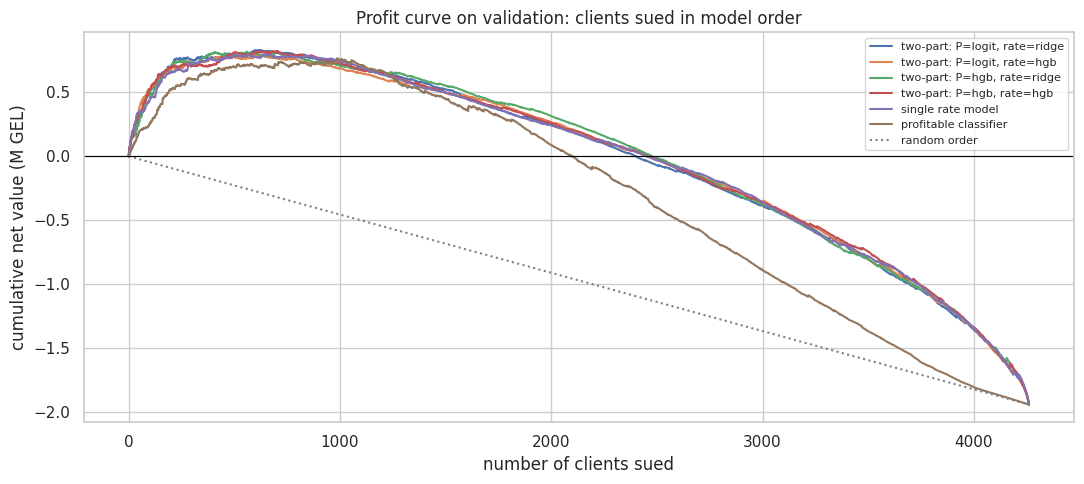

In [21]:
fig, ax = plt.subplots(figsize=(11, 5))
for name, c in curves.items():
    ax.plot(np.arange(len(c)), c / 1e6, label=name)
ax.plot([0, len(valid)], [0, valid.net_value_24m.sum() / 1e6], color="grey", ls=":", label="random order")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Profit curve on validation: clients sued in model order", xlabel="number of clients sued",
       ylabel="cumulative net value (M GEL)")
ax.legend(fontsize=8); plt.tight_layout(); savefig("profit_curves_valid"); plt.show()

In [22]:
two_part = [s for s in strategies if s["strategy"].startswith("two-part")]
chosen = max(two_part, key=lambda s: s["net_value"])
PA = chosen["strategy"].split("P=")[1].split(",")[0]
RB = chosen["strategy"].split("rate=")[1]
print("Chosen final design:", chosen["strategy"])
print("P(any payment) params:", best_a[PA]["params"], "| rate params:", best_b[RB]["params"])

Chosen final design: two-part: P=logit, rate=ridge
P(any payment) params: {'C': 0.01} | rate params: {'alpha': 1.0}


## 8. Calibration and decision margin

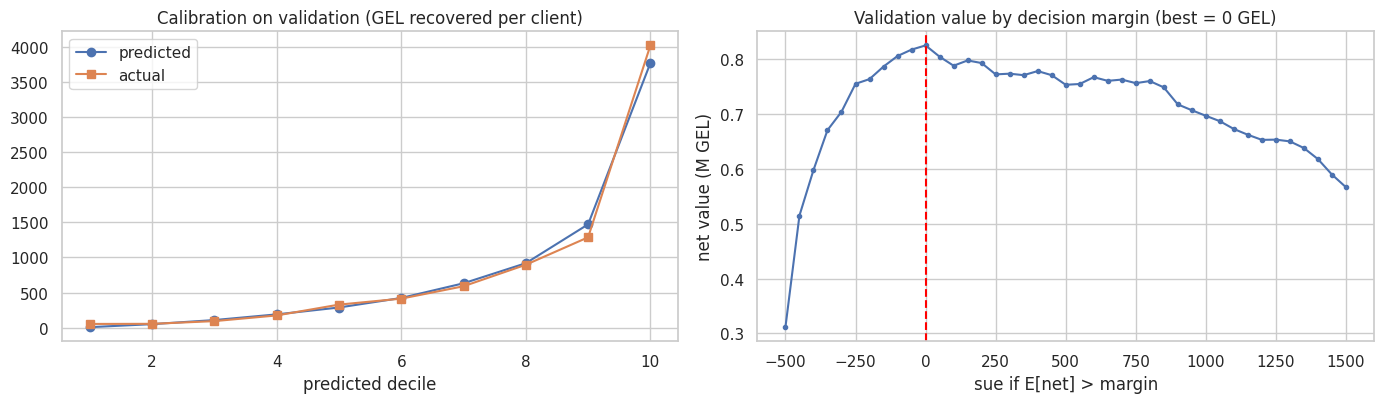

decile,1,2,3,4,5,6,7,8,9,10
pred_recovery,7.755,50.702,108.901,189.728,287.546,423.354,632.120,917.870,"1,470.924","3,766.035"
actual_recovery,53.658,55.187,93.792,174.705,328.590,413.704,590.071,895.924,"1,286.408","4,017.346"


Total predicted / actual recovery on validation: 0.993


In [23]:
p_final_a, r_final_b = best_a[PA]["est"], best_b[RB]["est"]
en_v, p_v, rate_v = expected_net(valid, p_final_a, r_final_b)

cal = pd.DataFrame({"pred_recovery": p_v * rate_v * valid.outst.values, "actual_recovery": valid.recovery_24m.values})
cal["decile"] = pd.qcut(cal.pred_recovery.rank(method="first"), 10, labels=False) + 1
cal_tab = cal.groupby("decile")[["pred_recovery", "actual_recovery"]].mean()

margins = np.arange(-500, 1501, 50)
margin_vals = [valid.net_value_24m[en_v > m].sum() for m in margins]
MARGIN = float(margins[int(np.argmax(margin_vals))])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(cal_tab.index, cal_tab.pred_recovery, marker="o", label="predicted")
axes[0].plot(cal_tab.index, cal_tab.actual_recovery, marker="s", label="actual")
axes[0].set(title="Calibration on validation (GEL recovered per client)", xlabel="predicted decile"); axes[0].legend()
axes[1].plot(margins, np.array(margin_vals) / 1e6, marker=".")
axes[1].axvline(MARGIN, color="red", ls="--")
axes[1].set(title=f"Validation value by decision margin (best = {MARGIN:,.0f} GEL)", xlabel="sue if E[net] > margin",
            ylabel="net value (M GEL)")
plt.tight_layout(); savefig("calibration_and_margin"); plt.show()
display(cal_tab.T)
print(f"Total predicted / actual recovery on validation: {cal.pred_recovery.sum() / cal.actual_recovery.sum():.3f}")

In [24]:
flat = valid.net_value_24m[en_v > MARGIN].sum() - valid.net_value_24m[en_v > 0].sum()
FINAL_MARGIN = MARGIN if flat > 0.05 * abs(valid.net_value_24m[en_v > 0].sum()) else 0.0
print(f"Gain of best margin over 0: {flat:,.0f} GEL → final decision margin: {FINAL_MARGIN:,.0f} GEL")

Gain of best margin over 0: 0 GEL → final decision margin: 0 GEL


## 9. Final model: refit on train + valid, evaluate once on test

The chosen configuration is refit on all labelled history before the test period, then scored on the test cohorts
(2025-07 … 2026-02), which no decision so far has looked at.

In [25]:
def build(kind, params):
    if kind == "logit": return make_logit(**params)
    if kind == "ridge": return make_ridge(**params)
    if kind == "hgb_clf": return make_hgb_clf(params["learning_rate"], params["max_leaf_nodes"], params["min_samples_leaf"])
    if kind == "hgb_reg": return make_hgb_reg(params["learning_rate"], params["max_leaf_nodes"], params["min_samples_leaf"])

A_KIND = "logit" if PA == "logit" else "hgb_clf"
B_KIND = "ridge" if RB == "ridge" else "hgb_reg"

def fit_two_part(df):
    pm = build(A_KIND, best_a[PA]["params"]).fit(df[FEATURES], df.any_payment)
    pos = df[df.any_payment == 1]
    rm = build(B_KIND, best_b[RB]["params"]).fit(pos[FEATURES], pos.recovery_rate_24m)
    return pm, rm

trval = pd.concat([train, valid])
final_p, final_r = fit_two_part(trval)
en_t, p_t, rate_t = expected_net(test, final_p, final_r)
sel_t = en_t > FINAL_MARGIN

bal_rule_t = test.outst > BEST_BAL
test_tab = pd.DataFrame([
    evaluate(test, np.ones(len(test)), "sue everyone"),
    evaluate(test, bal_rule_t, f"balance > {BEST_BAL:,.0f} GEL"),
    evaluate(test, rule_sel(test), RULE_NAME),
    evaluate(test, sel_t, "FINAL two-part model"),
    evaluate(test, test.net_value_24m > 0, "oracle"),
]).set_index("strategy")
display(test_tab)

t_pos = test.any_payment == 1
test_metrics = {
    "test_gini_any_payment": gini(test.any_payment, p_t),
    "test_spearman_rate_payers": pd.Series(rate_t[t_pos.values]).corr(pd.Series(test.recovery_rate_24m[t_pos].values), method="spearman"),
    "test_gini_profitable_by_Enet": gini(test.profitable, en_t),
    "test_net_value": test_tab.loc["FINAL two-part model", "net_value"],
    "test_vs_sue_all": test_tab.loc["FINAL two-part model", "vs_sue_all"],
    "test_capture": test_tab.loc["FINAL two-part model", "capture"],
    "test_cases": test_tab.loc["FINAL two-part model", "cases"],
    "test_pred_over_actual_recovery": (p_t * rate_t * test.outst.values).sum() / test.recovery_24m.sum(),
}
display(pd.Series(test_metrics).to_frame("value"))

,cases,share_sued,net_value,vs_sue_all,capture
strategy,,,,,
sue everyone,6359,1.000,"-3,706,895.867",0.000,0.000
"balance > 42,866 GEL",63,0.010,"-108,667.599","3,598,228.267",0.581
"rule: balance > 7,094 & bureau score > 367",419,0.066,"112,088.003","3,818,983.869",0.617
FINAL two-part model,861,0.135,"688,555.034","4,395,450.901",0.710
oracle,901,0.142,"2,486,071.560","6,192,967.426",1.000


,value
test_gini_any_payment,0.281
test_spearman_rate_payers,0.469
test_gini_profitable_by_Enet,0.538
test_net_value,"688,555.034"
test_vs_sue_all,"4,395,450.901"
test_capture,0.710
test_cases,861.000
test_pred_over_actual_recovery,1.129


In [26]:
rng = np.random.default_rng(SEED)
net_t = test.net_value_24m.values
gain_per_client = np.where(sel_t, 0, -net_t)
boot = np.array([gain_per_client[rng.integers(0, len(net_t), len(net_t))].sum() for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Improvement vs sue-everyone on test: {gain_per_client.sum():,.0f} GEL  (95% bootstrap CI {lo:,.0f} … {hi:,.0f})")
test_metrics.update({"test_gain_ci_low": lo, "test_gain_ci_high": hi})

Improvement vs sue-everyone on test: 4,395,451 GEL  (95% bootstrap CI 4,191,274 … 4,595,614)


🏃 View run FINAL | two-part model at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/77e84b0941b54ea5a8d91dcf7c8270b8
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0


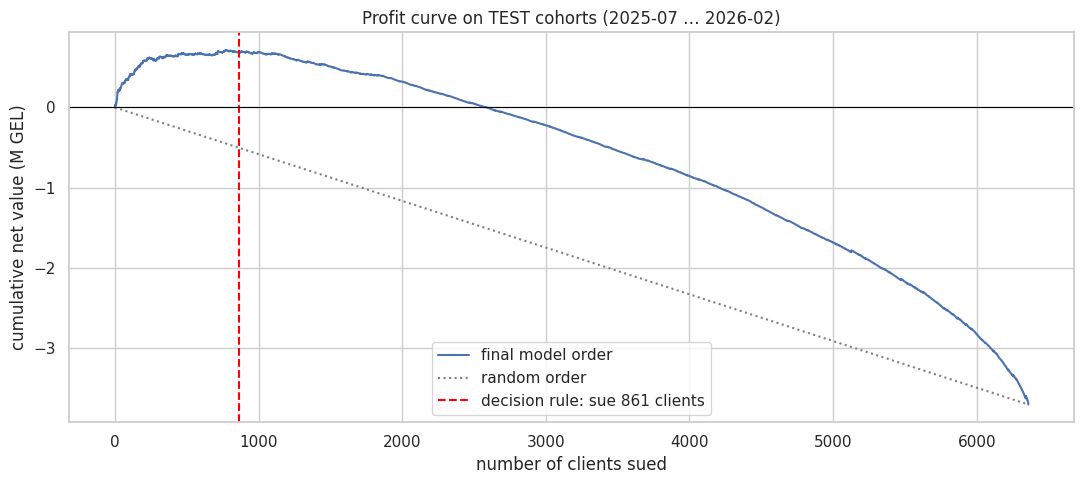

In [27]:
fig, ax = plt.subplots(figsize=(11, 5))
c = profit_curve(test, en_t)
ax.plot(np.arange(len(c)), c / 1e6, label="final model order")
ax.plot([0, len(test)], [0, test.net_value_24m.sum() / 1e6], color="grey", ls=":", label="random order")
ax.axvline(sel_t.sum(), color="red", ls="--", label=f"decision rule: sue {sel_t.sum():,} clients")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Profit curve on TEST cohorts (2025-07 … 2026-02)", xlabel="number of clients sued",
       ylabel="cumulative net value (M GEL)")
ax.legend(); plt.tight_layout(); savefig("profit_curve_test")

log_run("FINAL | two-part model", {"P_model": A_KIND, **{f"P_{k}": v for k, v in best_a[PA]["params"].items()},
                                   "rate_model": B_KIND, **{f"rate_{k}": v for k, v in best_b[RB]["params"].items()},
                                   "decision_margin": FINAL_MARGIN, "trained_on": "train+valid"},
        test_metrics, fig=fig, tags={"stage": "final"})
plt.show()

## 10. Robustness checks

In [28]:
rob_tr = data[data.split_actual_only == "train"]
rob_te = data[data.split_actual_only == "test"]
rp, rr = fit_two_part(rob_tr)
en_r, p_r, _ = expected_net(rob_te, rp, rr)
rob = pd.DataFrame([evaluate(rob_te, np.ones(len(rob_te)), "sue everyone"),
                    evaluate(rob_te, en_r > FINAL_MARGIN, "two-part model"),
                    evaluate(rob_te, rob_te.net_value_24m > 0, "oracle")]).set_index("strategy")
print(f"Actual-only split | Gini any_payment: {gini(rob_te.any_payment, p_r):.3f}")
display(rob)

cost_loan = FIXED_COST * test.n_loans.values + VAR_COST_RATE * test.outst.values
net_loan = test.recovery_24m.values - cost_loan
en_loan = p_t * rate_t * test.outst.values - cost_loan
fee = pd.DataFrame([evaluate(test, np.ones(len(test)), "sue everyone", net=net_loan),
                    evaluate(test, en_loan > FINAL_MARGIN, "two-part model (same model, new cost)", net=net_loan),
                    evaluate(test, net_loan > 0, "oracle", net=net_loan)]).set_index("strategy")
print("Fee charged per loan (test cohorts):")
display(fee)
log_run("robustness | actual-only split", {"design": "final two-part"},
        {"rob_gini_any": gini(rob_te.any_payment, p_r), "rob_vs_sue_all": rob.loc["two-part model", "vs_sue_all"],
         "rob_capture": rob.loc["two-part model", "capture"]}, tags={"stage": "robustness"})

Actual-only split | Gini any_payment: 0.349


,cases,share_sued,net_value,vs_sue_all,capture
strategy,,,,,
sue everyone,3514,1.000,"-1,547,984.957",0.000,0.000
two-part model,510,0.145,"737,052.374","2,285,037.331",0.696
oracle,570,0.162,"1,733,194.797","3,281,179.754",1.000


Fee charged per loan (test cohorts):


,cases,share_sued,net_value,vs_sue_all,capture
strategy,,,,,
sue everyone,6359,1.000,"-8,039,895.867",0.000,0.000
"two-part model (same model, new cost)",340,0.053,"283,370.860","8,323,266.727",0.837
oracle,695,0.109,"1,905,335.631","9,945,231.498",1.000


🏃 View run robustness | actual-only split at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/0f701c28530c49a986fc7d23bfc6cf01
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0


## 11. What drives the model?

P(any payment) — drop in AUC:


,importance,description
feature_019,0.017,Share of scheduled instalments paid late over ...
feature_012,0.014,Maximum end-of-day total balance across all ac...
feature_031,0.014,Credit bureau score at the last refresh before...
feature_003,0.011,"Total credit turnover across all accounts, mon..."
feature_039_missing,0.010,No declared income on file
feature_021,0.010,Number of times 30+ days past due on any facil...
feature_034,0.007,Internal behavioural score at the last monthly...
feature_036,0.006,Share of total bureau-reported exposure that i...
feature_011_missing,0.005,No deposit or savings product
feature_039,0.004,Declared monthly income stated at the client's...


Recovery rate | payment — drop in R²:


,importance,description
principal,0.257,Original principal
outst,0.207,Outstanding balance at court start
feature_031,0.045,Credit bureau score at the last refresh before...
feature_039_missing,0.040,No declared income on file
feature_019,0.037,Share of scheduled instalments paid late over ...
feature_003,0.029,"Total credit turnover across all accounts, mon..."
feature_034,0.027,Internal behavioural score at the last monthly...
feature_012,0.025,Maximum end-of-day total balance across all ac...
feature_039,0.025,Declared monthly income stated at the client's...
feature_036,0.019,Share of total bureau-reported exposure that i...


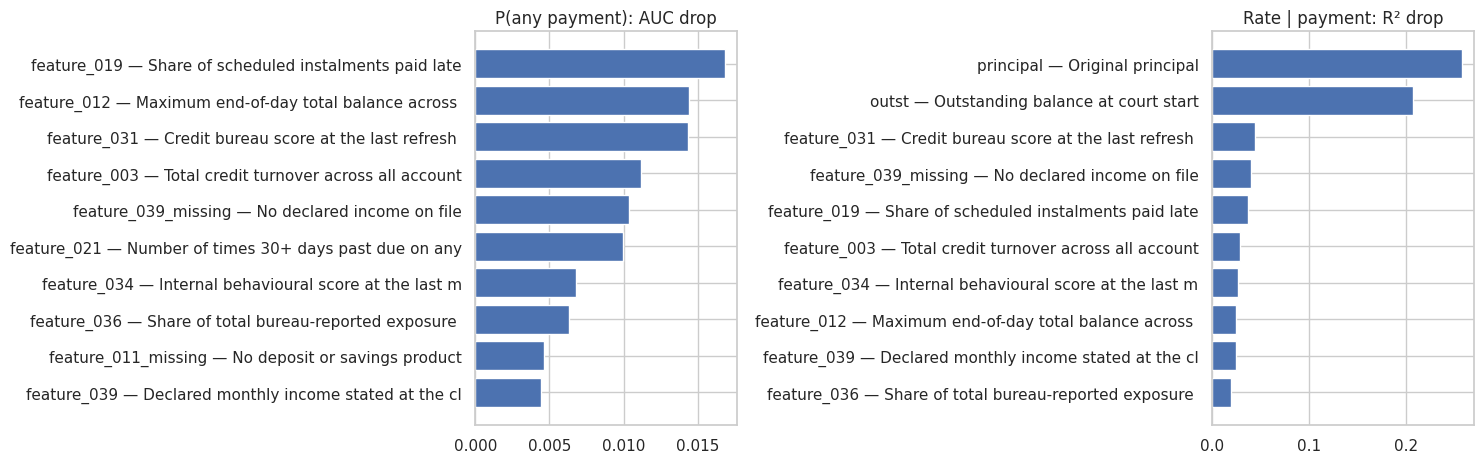

In [29]:
def perm_imp(model, X, y, scoring, n=10):
    r = permutation_importance(model, X, y, scoring=scoring, n_repeats=5, random_state=SEED, n_jobs=-1)
    imp = pd.Series(r.importances_mean, index=X.columns).sort_values(ascending=False).head(n)
    return imp.to_frame("importance").assign(description=lambda d: d.index.map(describe))

imp_p = perm_imp(final_p, test[FEATURES], test.any_payment, "roc_auc")
tp = test[test.any_payment == 1]
imp_r = perm_imp(final_r, tp[FEATURES], tp.recovery_rate_24m, "r2")
print("P(any payment) — drop in AUC:"); display(imp_p)
print("Recovery rate | payment — drop in R²:"); display(imp_r)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, imp, title in [(axes[0], imp_p, "P(any payment): AUC drop"), (axes[1], imp_r, "Rate | payment: R² drop")]:
    ax.barh([f"{i} — {d[:40]}" for i, d in zip(imp.index, imp.description)][::-1], imp.importance[::-1])
    ax.set_title(title)
plt.tight_layout(); savefig("feature_importance"); plt.show()

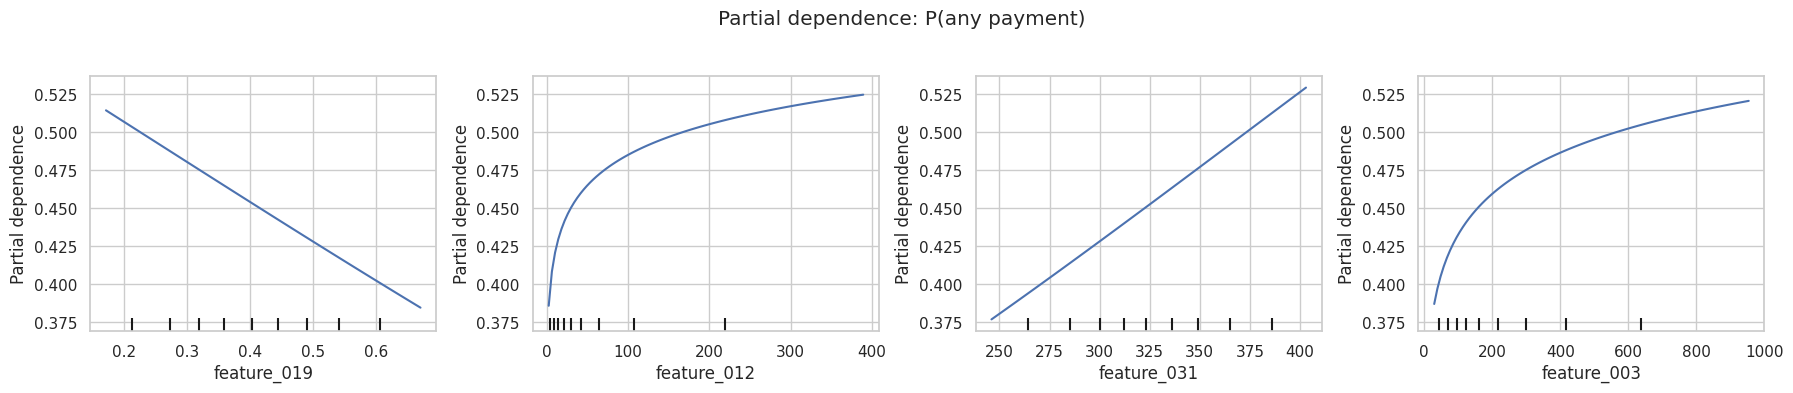

In [30]:
sample = test[FEATURES].astype(float).sample(min(2000, len(test)), random_state=SEED)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
PartialDependenceDisplay.from_estimator(final_p, sample, list(imp_p.index[:4]), ax=axes, kind="average")
fig.suptitle("Partial dependence: P(any payment)", y=1.03)
plt.tight_layout(); savefig("partial_dependence_any_payment"); plt.show()

In [31]:
if A_KIND == "logit":
    names = GEL_FEATURES + [c for c in FEATURES if c not in GEL_FEATURES]
    coef = pd.Series(final_p.named_steps["model"].coef_[0], index=names)
    top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)
    display(top.to_frame("std_coefficient").assign(
        effect=np.where(top > 0, "↑ more likely to pay", "↓ less likely to pay"),
        description=[describe(c) for c in top.index]))

,std_coefficient,effect,description
feature_039_missing,-0.205,↓ less likely to pay,No declared income on file
feature_031,0.204,↑ more likely to pay,Credit bureau score at the last refresh before...
feature_012,0.187,↑ more likely to pay,Maximum end-of-day total balance across all ac...
feature_003,0.177,↑ more likely to pay,"Total credit turnover across all accounts, mon..."
feature_019,-0.172,↓ less likely to pay,Share of scheduled instalments paid late over ...
feature_036,-0.157,↓ less likely to pay,Share of total bureau-reported exposure that i...
feature_034,0.141,↑ more likely to pay,Internal behavioural score at the last monthly...
feature_011_missing,-0.138,↓ less likely to pay,No deposit or savings product
feature_021,-0.131,↓ less likely to pay,Number of times 30+ days past due on any facil...
feature_006,-0.109,↓ less likely to pay,Share of cash withdrawals in total account out...


## 12. Strengths and weaknesses

In [32]:
seg = test.assign(en=en_t, p=p_t, rate=rate_t, sel=sel_t,
                  balance_band=pd.qcut(test.outst, 3, labels=["small", "medium", "large"]))
by_seg = seg.groupby("balance_band", observed=True).apply(lambda g: pd.Series({
    "clients": len(g), "gini_any_payment": gini(g.any_payment, g.p),
    "share_sued": g.sel.mean(), "net_if_model": g.net_value_24m[g.sel].sum(),
    "net_if_sue_all": g.net_value_24m.sum()}))
display(by_seg)

by_month = seg.groupby("PERIOD").apply(lambda g: pd.Series({
    "gini_any_payment": gini(g.any_payment, g.p), "pred/actual recovery": (g.p * g.rate * g.outst).sum() / g.recovery_24m.sum()}))
display(by_month.T)

,clients,gini_any_payment,share_sued,net_if_model,net_if_sue_all
balance_band,,,,,
small,"2,120.000",0.259,0.013,-116.550,"-1,079,066.074"
medium,"2,119.000",0.334,0.118,"111,935.437","-1,118,604.947"
large,"2,120.000",0.250,0.275,"576,736.148","-1,509,224.845"


PERIOD,2025/07,2025/08,2025/09,2025/10,2025/11,2025/12,2026/01,2026/02
gini_any_payment,0.343,0.246,0.297,0.245,0.316,0.286,0.215,0.296
pred/actual recovery,0.995,1.349,1.270,1.310,1.104,0.938,1.136,1.080


## 13. Save the final model and scores

In [33]:
bundle = {"p_model": final_p, "rate_model": final_r, "features": FEATURES, "decision_margin": FINAL_MARGIN,
          "cost": {"fixed": FIXED_COST, "var_rate": VAR_COST_RATE},
          "design": chosen["strategy"], "trained_on": "train+valid (2023-01 … 2025-06)"}
joblib.dump(bundle, MODEL_DIR / "final_two_part_model.joblib")

scored = test[["CLIENT_KEY", "PERIOD", "outst", "n_loans", "court_cost", "recovery_24m", "net_value_24m",
               "any_payment", "profitable"]].assign(p_any_payment=p_t, rate_given_payment=rate_t,
                                                    expected_net=en_t, sue=sel_t.astype(int))
try:
    scored.to_parquet(PROC_DIR / "test_scored.parquet", index=False)
except ImportError:
    scored.to_csv(PROC_DIR / "test_scored.csv", index=False)

if USE_MLFLOW:
    try:
        with mlflow.start_run(run_name="FINAL | model artifact"):
            mlflow.log_artifact(str(MODEL_DIR / "final_two_part_model.joblib"))
    except Exception as e:
        print("Artifact upload failed:", e)
print("Saved models/final_two_part_model.joblib and data/processed/test_scored (both gitignored)")

🏃 View run FINAL | model artifact at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0/runs/fe14f373748a49fe966898742909d018
🧪 View experiment at: https://dagshub.com/slosa23/Court-Recovery-Model.mlflow/#/experiments/0
Saved models/final_two_part_model.joblib and data/processed/test_scored (both gitignored)


## 14. Summary

- Experiments: logistic regression vs gradient boosting for **P(any payment)**, ridge vs gradient boosting for the **recovery rate**,
  plus a single-model challenger and a direct profitable classifier — all logged to MLflow.
- Selection by **validation net value in GEL**, not by AUC alone.
- The final two-part model is refit on 2023-01 … 2025-06 and evaluated once on the newest cohorts, with a bootstrap confidence interval,
  an actual-outcomes-only robustness check and a fee-per-loan sensitivity.